In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [2]:
# Load dataset
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", cancer.feature_names)
print("Target classes:", cancer.target_names)

Features shape: (569, 30)
Target shape: (569,)
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target classes: ['malignant' 'benign']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])


Training samples: 455
Testing samples: 114
Training features: 30


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training mean of first feature:",
      X_train_scaled[:, 0].mean())
print("Training std of first feature:",
      X_train_scaled[:, 0].std())

Training mean of first feature: -4.337433952909183e-15
Training std of first feature: 1.0


In [10]:
X_train_tensor = torch.tensor(X_train_scaled , dtype = torch.float32).to("cpu")
X_test_tensor = torch.tensor(X_test_scaled , dtype = torch.float32).to("cpu")

Y_train_tensor = torch.tensor(y_train , dtype = torch.float32).reshape(-1,1).to("cpu")
Y_test_tensor = torch.tensor(y_test , dtype = torch.float32).reshape(-1,1).to("cpu")

print("X_train:", X_train_tensor.shape)
print("y_train:", Y_train_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_test:", Y_test_tensor.shape)

X_train: torch.Size([455, 30])
y_train: torch.Size([455, 1])
X_test: torch.Size([114, 30])
y_test: torch.Size([114, 1])


In [11]:
class BreastCancerModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Linear(30,16),
            nn.ReLU(),
            nn.Linear(16,8),
            nn.ReLU(),
            nn.Linear(8,1)
        )

    def forward(self,x):
        return self.layer_stack(x)

model = BreastCancerModel().to("cpu")
print(model)

BreastCancerModel(
  (layer_stack): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(params = model.parameters() , lr = 0.001)

print("Loss function:", loss_fn)
print("Optimiser:", optimizer)

#BCEWithLogitsLoss: appropriate for binary classification with one output logit.

# Adam: adjusts the weights using gradients.

# lr=0.001: learning rate controlling the size of parameter updates.

Loss function: BCEWithLogitsLoss()
Optimiser: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [13]:
epochs = 100
train_losses = []

for epoch in range(epochs):
    model.train()
    logits = model(X_train_tensor)

    loss = loss_fn(logits , Y_train_tensor)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    if(epoch+1)%10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [10/100], Loss: 0.6653
Epoch [20/100], Loss: 0.6366
Epoch [30/100], Loss: 0.5939
Epoch [40/100], Loss: 0.5381
Epoch [50/100], Loss: 0.4779
Epoch [60/100], Loss: 0.4177
Epoch [70/100], Loss: 0.3609
Epoch [80/100], Loss: 0.3100
Epoch [90/100], Loss: 0.2664
Epoch [100/100], Loss: 0.2302


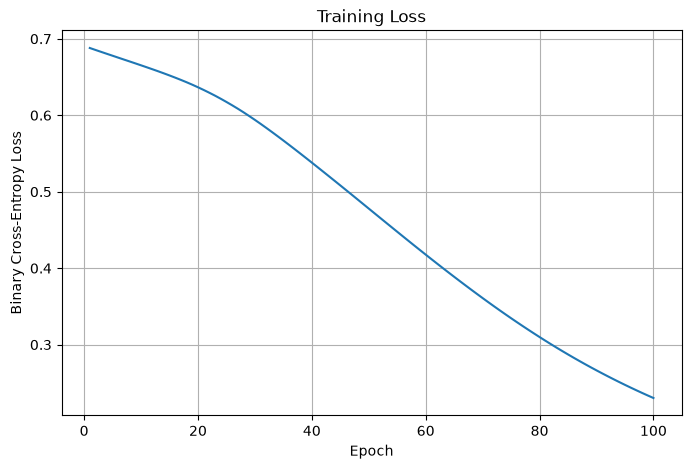

In [15]:
plt.figure(figsize = (8,5))

plt.plot(range(1,epochs+1) , train_losses)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss")
plt.grid(True)

plt.show()

In [17]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test_tensor)
    test_probabilities = torch.sigmoid(test_logits)
    Y_pred = (test_probabilities >= 0.5).int()

Y_pred_np = Y_pred.cpu().numpy().ravel()
Y_test_np = Y_test_tensor.cpu().numpy().ravel().astype(int)

print("First 10 probabilities:")
print(test_probabilities[:10].cpu().numpy().ravel())

print("\nFirst 10 predicted classes:")
print(Y_pred_np[:10])

First 10 probabilities:
[0. 0. 1. 0. 0. 0. 1. 0. 0. 0.]

First 10 predicted classes:
[0 0 1 0 0 0 1 0 0 0]


In [ ]:
accuracy = accuracy_score(Y_test_np , Y_pred_np)

precision_malignant = precision_score(Y_test_np , Y_pred_np, pos_label = 0, zero_division = 0)
recall_malignant = recall_score(Y_test_np , Y_pred_np, pos_label = 0, zero_division = 0)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (malignant): {precision_malignant:.4f}")
print(f"Recall (malignant): {recall_malignant:.4f}")

# pos_label=0: Tells scikit-learn to treat class 0 as the positive class for these metrics.
# zero_division=0: Returns 0 if the precision or recall calculation has a zero denominator.

# Accuracy: fraction of all samples classified correctly.
# Precision (malignant): among samples predicted malignant, how many were actually malignant?
# Recall (malignant): among all actual malignant samples, how many did the model identify?

Accuracy: 0.5088
Precision (malignant): 0.4125
Recall (malignant): 0.7857


In [20]:
cm = confusion_matrix(Y_test_np , Y_pred_np , labels=[0,1])
print(cm)

[[33  9]
 [47 25]]


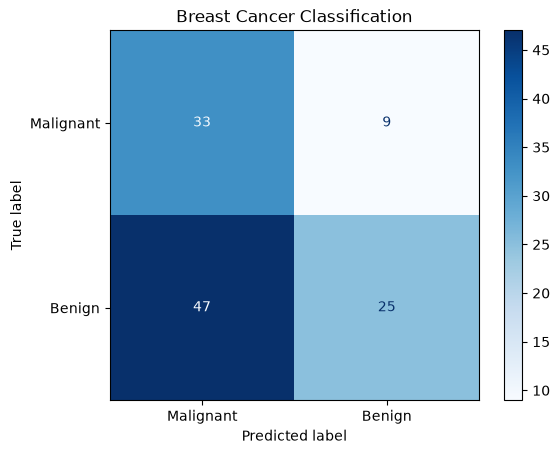

In [22]:
disp = ConfusionMatrixDisplay(confusion_matrix = cm , display_labels = ["Malignant" , "Benign"])
disp.plot(cmap = "Blues" , values_format = "d")
plt.title("Breast Cancer Classification")
plt.show()

In [ ]:
false_negative_indices = np.where((Y_test_np == 0) & (Y_pred_np == 1))[0]
false_positive_indices = np.where((Y_test_np == 1) & (Y_pred_np == 0))[0]

print("False negatives:", len(false_negative_indices))
print("False positives:", len(false_positive_indices))

# False negative: a malignant sample predicted as benign. The model misses a malignant case.
# False positive: a benign sample predicted as malignant. The model incorrectly flags a benign case.

False negatives: 9
False positives: 47


In [27]:
print(
    classification_report(
        Y_test_np,
        Y_pred_np,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

   Malignant       0.41      0.79      0.54        42
      Benign       0.74      0.35      0.47        72

    accuracy                           0.51       114
   macro avg       0.57      0.57      0.51       114
weighted avg       0.62      0.51      0.50       114

